In [46]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [47]:
# read in all the words
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [48]:
len(words)

32033

In [49]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}  # stoi: string to integer
stoi["."] = 0  # add a special token to represent the start/end of a word
itos = {i: s for s, i in stoi.items()}  # itos: integer to string
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [ ]:
# build the dataset

block_size = (
    3  # context length: how many characters do we take to predict the next one?
)
X, Y = [], []
for w in words:
    # print(w)
    context = [0] * block_size  # initialize the context with all start-of-word tokens
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print("".join(itos[i] for i in context), "----->", itos[ix])
        context = context[1:] + [ix]  # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

In [52]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

### training split, dev/validation split, test split

#### 80% training, 10% validation, 10% test


In [66]:
# build the dataset


def build_dataset(words):
    block_size = (
        3  # context length: how many characters do we take to predict the next one?
    )
    X, Y = [], []
    for w in words:
        # print(w)
        context = [
            0
        ] * block_size  # initialize the context with all start-of-word tokens
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "----->", itos[ix])
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y


import random

random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])  # first 80%
Xdev, Ydev = build_dataset(words[n1:n2])  # middle 10%
Xte, Yte = build_dataset(words[n2:])  # last 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [53]:
C = torch.randn((27, 2))  # 27 characters, 2-dimensional representation

In [54]:
emb = C[
    X
]  # (32, 3, 2) 32 examples, 3 characters in context, 2-dimensional representation
emb.shape

torch.Size([32, 3, 2])

In [55]:
W1 = torch.randn(
    (6, 100)
)  # 6 inputs (3*2) because 2 dimensions per character and 3 embeddings, 100 outputs
b1 = torch.randn(100)  # 100 outputs

In [56]:
h = torch.tanh(
    emb.view(-1, 6) @ W1 + b1
)  # -1 means "figure out the size of this dimension based on the other dimensions and the total number of elements" or alternatively use emb.shape[0] to get the number of examples. (32, 6) @ (6, 100) + (100,) = (32, 100)

In [57]:
h

tensor([[-0.9917, -0.5848, -0.8350,  ..., -0.1596,  1.0000,  0.3665],
        [-0.9332, -0.8211,  0.4628,  ...,  0.8763,  0.9996, -0.5143],
        [-0.9996, -0.9958,  0.6024,  ..., -0.0275,  0.9954, -0.7996],
        ...,
        [-0.9781, -0.6969,  0.2642,  ..., -0.9335, -1.0000,  0.9783],
        [ 0.8001, -0.9802,  0.6641,  ...,  0.3838, -0.8936,  0.7212],
        [ 0.9940,  0.9994,  0.9707,  ..., -0.8126,  0.6836, -0.4240]])

In [58]:
h.shape

torch.Size([32, 100])

In [59]:
W2 = torch.randn((100, 27))  # 100 inputs, 27 outputs
b2 = torch.randn(27)  # 27 outputs

In [60]:
logits = h @ W2 + b2  # (32, 100) @ (100, 27) + (27,) = (32, 27)

In [61]:
logits.shape

torch.Size([32, 27])

In [62]:
counts = logits.exp()  # (32, 27)

In [63]:
prob = counts / counts.sum(1, keepdims=True)  # (32, 27)

In [64]:
prob.shape

torch.Size([32, 27])

In [65]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(16.1317)

### Rewrote everything clearly


In [67]:
Xtr.shape, Ytr.shape  # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [86]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, 10), generator=g)  # 27 characters, 10-dimensional representation
W1 = torch.randn(
    (30, 200), generator=g
)  # 30 inputs (3*10) because 10 dimensions per character and 3 embeddings, 200 outputs
b1 = torch.randn(200, generator=g)  # 200 outputs
W2 = torch.randn((200, 27), generator=g)  # 200 inputs, 27 outputs
b2 = torch.randn(27, generator=g)  # 27 outputs
parameters = [C, W1, b1, W2, b2]

In [87]:
sum(p.nelement() for p in parameters)  # number of parameters in the model

11897

In [88]:
for p in parameters:
    p.requires_grad = (
        True  # make sure we can compute gradients with respect to these variables
    )

In [89]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [90]:
lri = []
lossi = []
stepi = []

In [103]:
for i in range(200000):
    # minibatch construct
    ix = torch.randint(
        0, Xtr.shape[0], (32,)
    )  # sample 32 random integers from 0 to the number of examples

    # forwards pass
    emb = C[
        Xtr[ix]
    ]  # (32, 3, 10) 32 examples, 3 characters in context, 10-dimensional representation
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 200)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(
        logits, Ytr[ix]
    )  # this is the same as the loss we calculated above, but more numerically stable

    # print(loss.item())

    # backwards pass
    for p in parameters:
        p.grad = None  # set the gradient to zero before running the backward pass
    loss.backward()

    # update
    # lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01  # learning rate decay
    for p in parameters:
        p.data += -lr * p.grad  # gradient descent

    # track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

print(loss.item())

1.7915128469467163


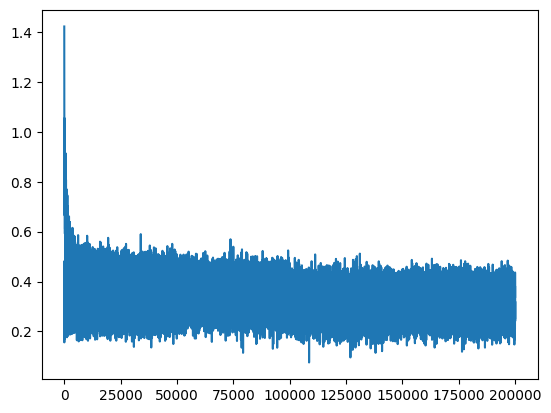

In [104]:
plt.plot(stepi, lossi)

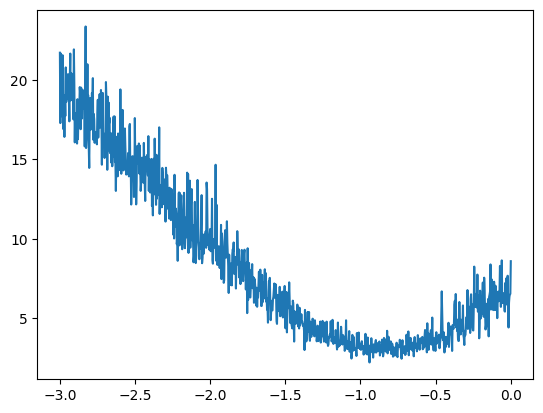

In [166]:
plt.plot(lri, lossi)

In [105]:
emb = C[
    Xtr
]  # (32, 3, 10) 32 examples, 3 characters in context, 10-dimensional representation
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 200)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(
    logits, Ytr
)  # this is the same as the loss we calculated above, but more numerically stable
loss

tensor(2.1018, grad_fn=<NllLossBackward0>)

In [106]:
emb = C[
    Xdev
]  # (32, 3, 10) 32 examples, 3 characters in context, 10-dimensional representation
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 200)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(
    logits, Ydev
)  # this is the same as the loss we calculated above, but more numerically stable
loss

tensor(2.1477, grad_fn=<NllLossBackward0>)

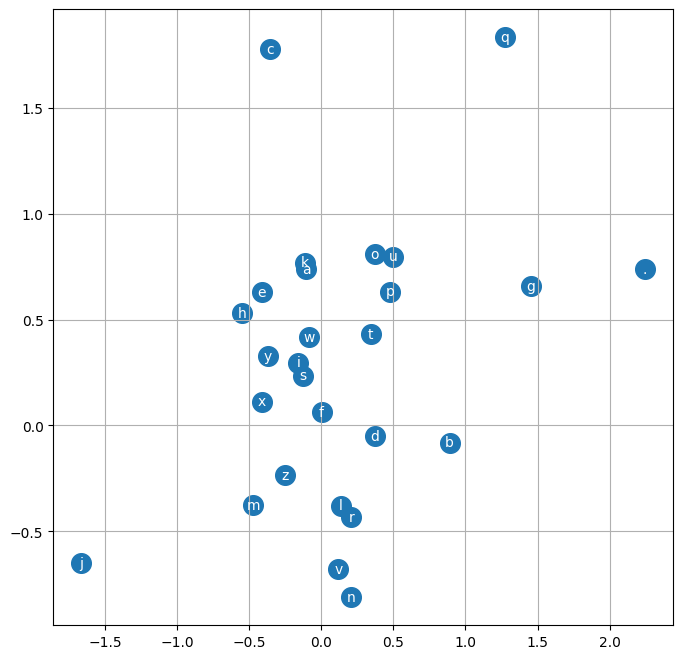

In [107]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(
        C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white"
    )
plt.grid("minor")

In [109]:
# sample for the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size  # initialize the context with all start-of-word tokens
    while True:
        emb = C[torch.tensor([context])]  # (1, block_size, d)
        h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (1, 200)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]  # crop and append
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

carmah.
ambrilli.
kimlyn.
tate.
skansh.
ejanonen.
den.
rhe.
kaeli.
ner.
kia.
chaiivon.
legnto.
bron.
cadeniyah.
roilea.
jadilyn.
jermaijarynix.
kael.
dura.
